In [3]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.15.0+cpu
Torchvision version: 0.29.2+cpu
CUDA available: False


In [4]:
from pathlib import Path

# Define cleaned dataset location
CLEANED_DIR = Path(
    r"A:\Crop-Disease-Detection\dataset\cleaned"
)

# Verify the directory
print("Cleaned dataset exists:", CLEANED_DIR.exists())

# Verify splits
for split in ["Train", "Val", "Test"]:
    print(split, "exists:", (CLEANED_DIR / split).exists())

Cleaned dataset exists: True
Train exists: True
Val exists: True
Test exists: True


In [5]:
from PIL import Image
from torchvision import transforms
from pathlib import Path

# Select one sample image from the cleaned dataset
sample_image_path = next(
    (CLEANED_DIR / "Train").glob("*/*.jpg"),
    None
)

# Load image
image = Image.open(sample_image_path).convert("RGB")

print("Original image size:", image.size)
print("Original image mode:", image.mode)

# Define ResNet50 preprocessing
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Apply preprocessing
image_tensor = preprocess(image)

print("\nPreprocessed tensor shape:", image_tensor.shape)
print("Minimum tensor value:", image_tensor.min().item())
print("Maximum tensor value:", image_tensor.max().item())

Original image size: (256, 256)
Original image mode: RGB

Preprocessed tensor shape: torch.Size([3, 224, 224])
Minimum tensor value: -1.7582842111587524
Maximum tensor value: 2.0996952056884766


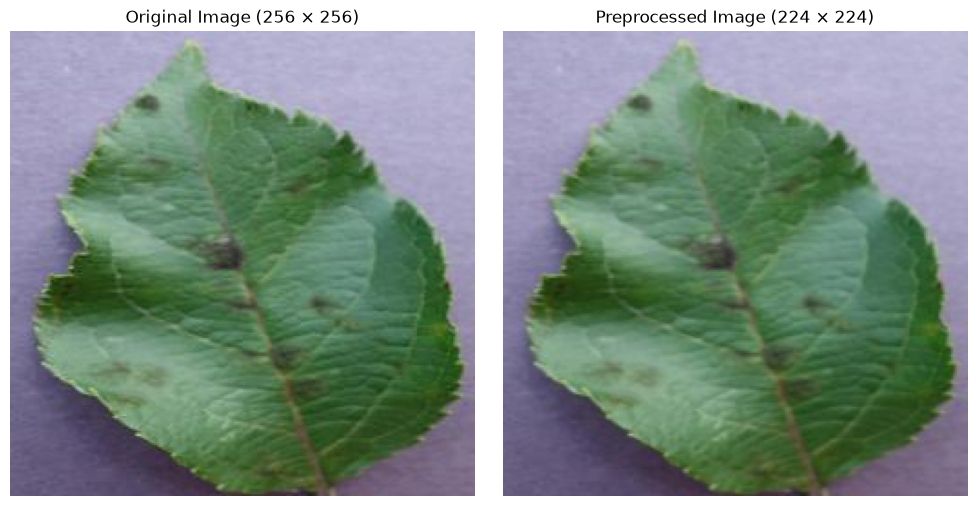

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Convert normalized tensor back to displayable RGB values
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

tensor_image = image_tensor.permute(1, 2, 0).numpy()

display_image = tensor_image * std + mean
display_image = np.clip(display_image, 0, 1)

# Display both images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image (256 × 256)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(display_image)
plt.title("Preprocessed Image (224 × 224)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
from torchvision import transforms

# Basic preprocessing for ResNet50
resnet50_preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("ResNet50 preprocessing pipeline created!")

ResNet50 preprocessing pipeline created!


In [8]:
from torchvision import transforms

train_transform = transforms.Compose([

    # Resize image
    transforms.Resize((224, 224)),

    # Random horizontal flip
    transforms.RandomHorizontalFlip(p=0.5),

    # Random vertical flip
    transforms.RandomVerticalFlip(p=0.5),

    # Random rotation between -15 and +15 degrees
    transforms.RandomRotation(degrees=15),

    # Slight color variations
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),

    # Convert image into tensor
    transforms.ToTensor(),

    # ResNet50 normalization
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training augmentation pipeline created!")

Training augmentation pipeline created!


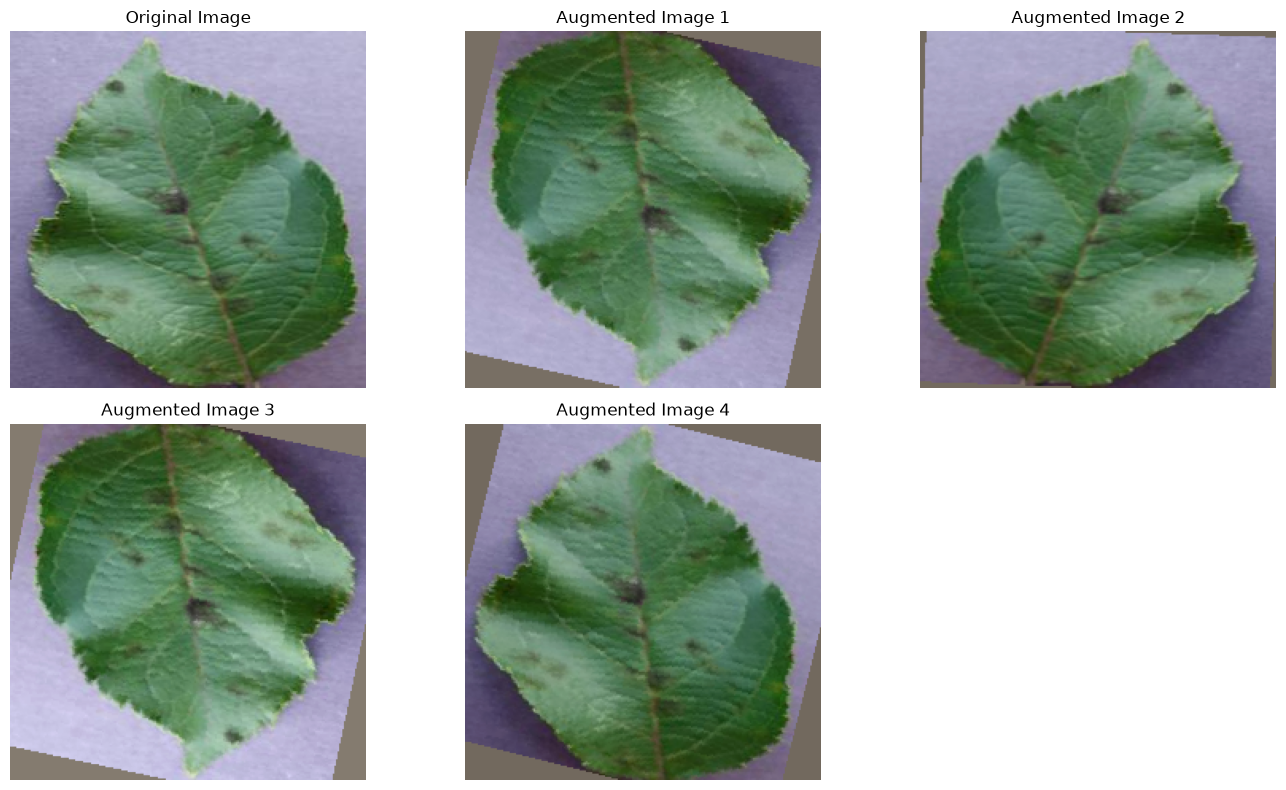

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Find one training image
sample_image_path = next(
    path for path in (CLEANED_DIR / "Train").glob("*/*")
    if path.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

# Load original image
sample_image = Image.open(sample_image_path).convert("RGB")

# ResNet50 normalization values
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

# Display original and augmented images
plt.figure(figsize=(14, 8))

plt.subplot(2, 3, 1)
plt.imshow(sample_image)
plt.title("Original Image")
plt.axis("off")

for i in range(4):

    # Apply random augmentation
    augmented_tensor = train_transform(sample_image)

    # Convert tensor to displayable image
    augmented_image = augmented_tensor.permute(1, 2, 0).numpy()

    # Reverse normalization for visualization
    augmented_image = augmented_image * std + mean
    augmented_image = np.clip(augmented_image, 0, 1)

    plt.subplot(2, 3, i + 2)
    plt.imshow(augmented_image)
    plt.title(f"Augmented Image {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
train_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomVerticalFlip(p=0.5),

    # Fill empty rotation areas with neutral color
    transforms.RandomRotation(
        degrees=15,
        fill=(124, 116, 104)
    ),

    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Improved augmentation pipeline created!")

Improved augmentation pipeline created!


In [12]:
from torchvision import transforms

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Validation and testing transforms created!")

Validation and testing transforms created!


In [13]:
from torchvision.datasets import ImageFolder

# Load training dataset with augmentation
train_dataset = ImageFolder(
    root=CLEANED_DIR / "Train",
    transform=train_transform
)

# Load validation dataset without augmentation
val_dataset = ImageFolder(
    root=CLEANED_DIR / "Val",
    transform=val_test_transform
)

# Load testing dataset without augmentation
test_dataset = ImageFolder(
    root=CLEANED_DIR / "Test",
    transform=val_test_transform
)

# Display dataset information
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

print("\nNumber of classes:", len(train_dataset.classes))

# Verify class mappings
assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

print("Class mappings are consistent!")

Training images: 53672
Validation images: 12060
Testing images: 1353

Number of classes: 29
Class mappings are consistent!


In [14]:
# Create a Dataloader 
# A data loader takes images from your dataset and provides them to the model in smaller groups called batches.
# For example, instead of loading all 53672 training images into memory at once, we can load 32 images at a time.


from torch.utils.data import DataLoader

# Batch size
BATCH_SIZE = 32

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

# Validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully!")

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


DataLoaders created successfully!
Training batches: 1678
Validation batches: 377
Testing batches: 43


In [15]:
# Get one batch from training data
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("First 10 labels:", labels[:10])

print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First 10 labels: tensor([ 7, 20, 25, 21, 19, 19, 22,  6,  2, 18])
Image data type: torch.float32
Label data type: torch.int64


In [16]:
# Display all class names and their numerical labels

print("Total classes:", len(train_dataset.classes))
print("\nClass-to-index mapping:\n")

for class_name, class_index in train_dataset.class_to_idx.items():
    print(f"{class_index}: {class_name}")

Total classes: 29

Class-to-index mapping:

0: Apple - Apple Scab
1: Apple - Black Rot
2: Apple - Cedar Apple Rust
3: Apple - Healthy
4: Bell Pepper - Bacterial Spot
5: Bell Pepper - Healthy
6: Cherry - Healthy
7: Cherry - Powdery Mildew
8: Corn (Maize) - Cercospora Leaf Spot
9: Corn (Maize) - Common Rust
10: Corn (Maize) - Healthy
11: Corn (Maize) - Northern Leaf Blight
12: Grape - Black Rot
13: Grape - Esca (Black Measles)
14: Grape - Healthy
15: Grape - Leaf Blight
16: Peach - Bacterial Spot
17: Peach - Healthy
18: Potato - Early Blight
19: Potato - Healthy
20: Potato - Late Blight
21: Strawberry - Healthy
22: Strawberry - Leaf Scorch
23: Tomato - Bacterial Spot
24: Tomato - Early Blight
25: Tomato - Healthy
26: Tomato - Late Blight
27: Tomato - Septoria Leaf Spot
28: Tomato - Yellow Leaf Curl Virus


In [ ]:
import pandas as pd

class_distribution = pd.DataFrame({
    "Class": train_dataset.classes,
    "Train": [
        train_dataset.targets.count(i)
        for i in range(len(train_dataset.classes))
    ],
    "Validation": [
        val_dataset.targets.count(i)
        for i in range(len(val_dataset.classes))
    ],
    "Test": [
        test_dataset.targets.count(i)
        for i in range(len(test_dataset.classes))
    ]
})

display(class_distribution)

print("\nTotal training images:",
    class_distribution["Train"].sum())

print("Total validation images:",
    class_distribution["Validation"].sum())

print("Total testing images:",
    class_distribution["Test"].sum())

,Class,Train,Validation,Test
0,Apple - Apple Scab,2016,453,51
1,Apple - Black Rot,1987,447,50
2,Apple - Cedar Apple Rust,1760,396,44
3,Apple - Healthy,2000,449,51
4,Bell Pepper - Bacterial Spot,1913,430,48
5,Bell Pepper - Healthy,1988,447,50
6,Cherry - Healthy,1826,410,46
7,Cherry - Powdery Mildew,1683,378,43
8,Corn (Maize) - Cercospora Leaf Spot,1642,369,41
9,Corn (Maize) - Common Rust,1907,429,48



Total training images: 53672
Total validation images: 12060
Total testing images: 1353


In [20]:
from pathlib import Path

# Define reports directory
REPORT_DIR = Path(
    r"A:\Crop-Disease-Detection\dataset\reports"
)

# Ensure directory exists
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Reports directory exists:", REPORT_DIR.exists())

Reports directory exists: True


In [21]:
import json

# Get class-to-index mapping
class_mapping = train_dataset.class_to_idx

# Save mapping
mapping_path = REPORT_DIR / "class_mapping.json"

with open(mapping_path, "w") as file:
    json.dump(class_mapping, file, indent=4)

print("Class mapping saved successfully!")
print("Location:", mapping_path)

Class mapping saved successfully!
Location: A:\Crop-Disease-Detection\dataset\reports\class_mapping.json


In [22]:
import pandas as pd
import matplotlib.pyplot as plt

distribution_path = REPORT_DIR / "cleaned_class_distribution.csv"

class_distribution = pd.read_csv(distribution_path)

class_distribution.head()

,Split,Class,Image_Count
0,Train,Apple - Apple Scab,2016
1,Train,Apple - Black Rot,1987
2,Train,Apple - Cedar Apple Rust,1760
3,Train,Apple - Healthy,2000
4,Train,Bell Pepper - Bacterial Spot,1913


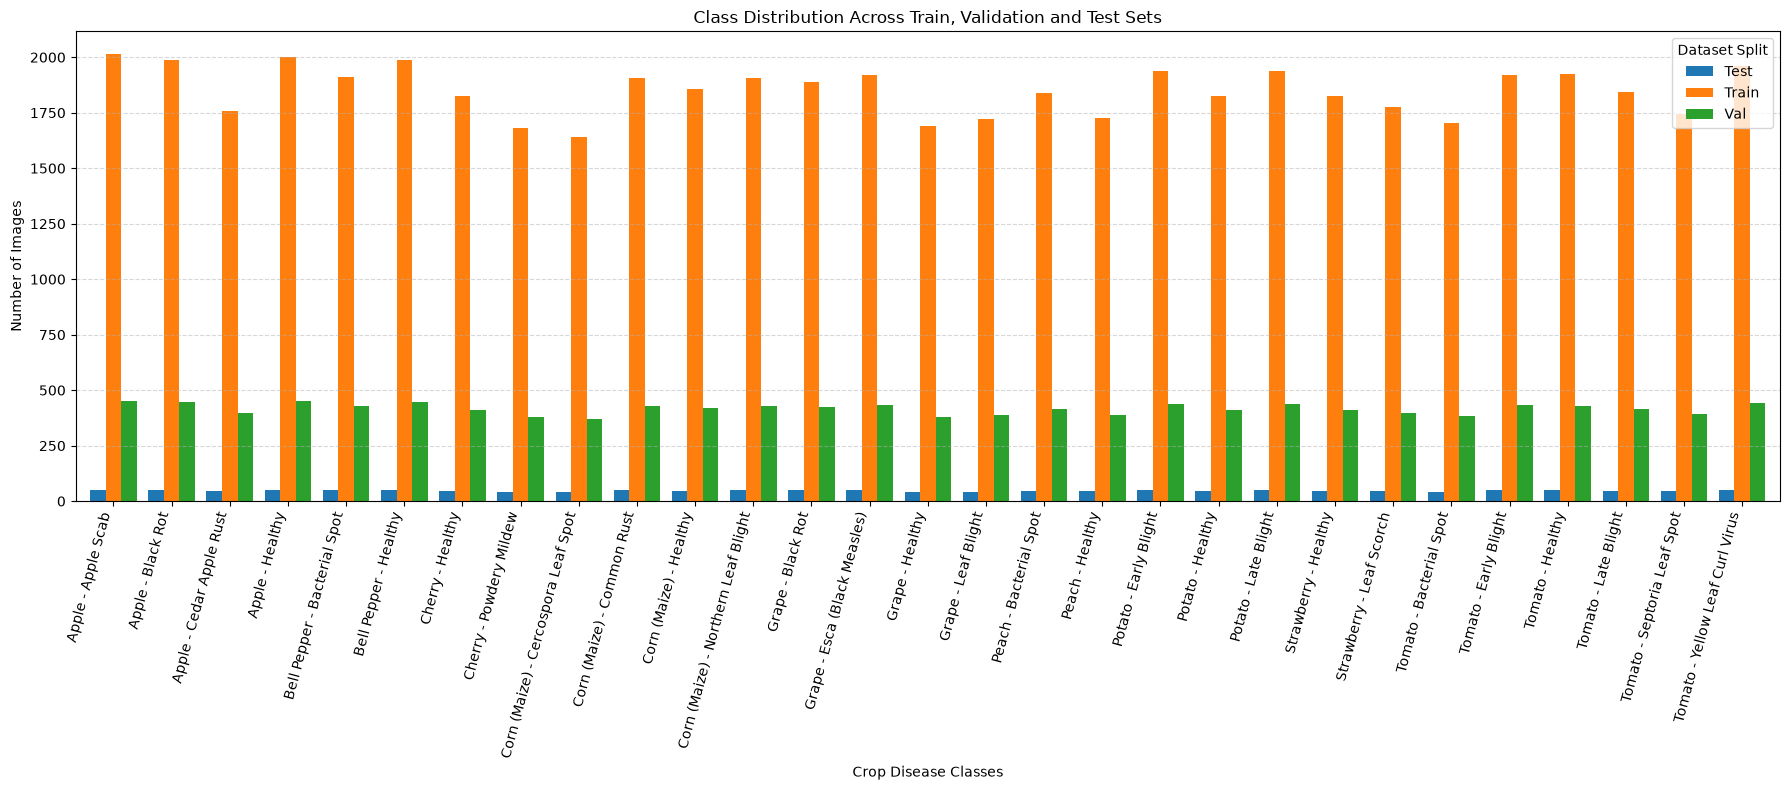

Chart saved at: A:\Crop-Disease-Detection\dataset\reports\class_distribution.png


In [23]:
# Convert the data into a format suitable for plotting
distribution_pivot = class_distribution.pivot(
    index="Class",
    columns="Split",
    values="Image_Count"
)

# Plot the chart
distribution_pivot.plot(
    kind="bar",
    figsize=(18, 8),
    width=0.8
)

plt.title("Class Distribution Across Train, Validation and Test Sets")
plt.xlabel("Crop Disease Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=75, ha="right")
plt.legend(title="Dataset Split")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

# Save the chart
chart_path = REPORT_DIR / "class_distribution.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

print("Chart saved at:", chart_path)